### Research Agent
The goal of research is to gather the context requested by the research brief.

Here is our overall research flow:

![scope_workflow](../notebook_images/scoping_workflow.png)


####  The agent follows 

1. LLM Decision Node: Analyzes the current state and decides whether to make tool calls or provide a final response
2. Tool Execution Node: Executes search tools when the LLM determines more information is needed
3. Research Compression Node: Summarizes and compresses research findings for efficient processing
4. Routing Logic: Determines workflow continuation based on LLM decisions

![research_agent_flow](../notebook_images/research_agent.png)

- Think like a human researcher with limited time - this prevents the "spin-out problem" where agents continue searching indefinitely.

In [205]:
research_agent_prompt =  """You are a research assistant conducting research on the user's input topic. For context, today's date is {date}.

<Task>
Your job is to use tools to gather information about the user's input topic.
You can use any of the tools provided to you to find resources that can help answer the research question. You can call these tools in series or in parallel, your research is conducted in a tool-calling loop.
</Task>

<Available Tools>
You have access to two main tools:
1. **tavily_search**: For conducting web searches to gather information
2. **think_tool**: For reflection and strategic planning during research

**CRITICAL: Use think_tool after each search to reflect on results and plan next steps**
</Available Tools>

<Instructions>
Think like a human researcher with limited time. Follow these steps:

1. **Read the question carefully** - What specific information does the user need?
2. **Start with broader searches** - Use broad, comprehensive queries first
3. **After each search, pause and assess** - Do I have enough to answer? What's still missing?
4. **Execute narrower searches as you gather information** - Fill in the gaps
5. **Stop when you can answer confidently** - Don't keep searching for perfection
</Instructions>

<Hard Limits>
**Tool Call Budgets** (Prevent excessive searching):
- **Simple queries**: Use 2-3 search tool calls maximum
- **Complex queries**: Use up to 5 search tool calls maximum
- **Always stop**: After 5 search tool calls if you cannot find the right sources

**Stop Immediately When**:
- You can answer the user's question comprehensively
- You have 3+ relevant examples/sources for the question
- Your last 2 searches returned similar information
</Hard Limits>

<Show Your Thinking>
After each search tool call, use think_tool to analyze the results:
- What key information did I find?
- What's missing?
- Do I have enough to answer the question comprehensively?
- Should I search more or provide my answer?
</Show Your Thinking>
"""

In [236]:
import os 
from dotenv import load_dotenv
load_dotenv()

# Disable deprecated LangChain v1 tracer if present
os.environ.pop("LANGCHAIN_TRACING", None)

# Enable LangChain tracing v2 (optional; no-op without API key)
os.environ["LANGCHAIN_TRACING_V2"] = os.getenv("LANGCHAIN_TRACING_V2", "true")

# Set GROQ key from environment
os.environ["GROQ_API_KEY"] = groq_api_key = os.getenv("GROQ_API_KEY")

### State and Schemas 

In [207]:
import operator 
from typing_extensions import TypedDict
from typing import Annotated , List  , Sequence 
from pydantic import BaseModel , Field 
from langchain_core.messages import BaseMessage 
from langgraph.graph.message import add_messages 


In [208]:
class ResearcherState(TypedDict) : 
    """State for the research agent containing message history and research metadata."""

    researcher_messages : Annotated[Sequence[BaseMessage] ,add_messages]
    tool_call_iterations : int 
    research_topic : str 
    compressed_research : str 
    raw_notes : Annotated[List[str] , operator.add]

In [209]:
class ResearcherOutputState(TypedDict) : 
    """Output state for the research agent containing final research results."""

    researcher_messages : Annotated[Sequence[BaseMessage] ,add_messages]
    compressed_research : str 
    raw_notes : Annotated[List[str] , operator.add]
    


In [210]:
class ClarifyWithUser(BaseModel) : 
    need_clarification : bool = Field(description="whether the user needs to be asked a clarifying question.")
    question : str = Field(description= "A question to ask the user to clarify the report scope.")
    verification : str = Field(description="Verify message that we will start research after the user has provided the necessary information.")

class ResearchQuestion(BaseModel) :
    research_brief : str = Field(description="A research question that will be used to guide the research.")

In [211]:
class Summary(BaseModel) : 
    """Schema for webpage content summarization."""

    summary : str = Field(description="Concise summary of the webpage content")
    key_excerpts : str = Field(description="Important quotes and excerpts from the content")
    

In [212]:
summarize_webpage_prompt = """You are tasked with summarizing the raw content of a webpage retrieved from a web search. Your goal is to create a summary that preserves the most important information from the original web page. This summary will be used by a downstream research agent, so it's crucial to maintain the key details without losing essential information.

Here is the raw content of the webpage:

<webpage_content>
{webpage_content}
</webpage_content>

Please follow these guidelines to create your summary:

1. Identify and preserve the main topic or purpose of the webpage.
2. Retain key facts, statistics, and data points that are central to the content's message.
3. Keep important quotes from credible sources or experts.
4. Maintain the chronological order of events if the content is time-sensitive or historical.
5. Preserve any lists or step-by-step instructions if present.
6. Include relevant dates, names, and locations that are crucial to understanding the content.
7. Summarize lengthy explanations while keeping the core message intact.

When handling different types of content:

- For news articles: Focus on the who, what, when, where, why, and how.
- For scientific content: Preserve methodology, results, and conclusions.
- For opinion pieces: Maintain the main arguments and supporting points.
- For product pages: Keep key features, specifications, and unique selling points.

Your summary should be significantly shorter than the original content but comprehensive enough to stand alone as a source of information. Aim for about 25-30 percent of the original length, unless the content is already concise.

Present your summary in the following format:

```
{{
   "summary": "Your summary here, structured with appropriate paragraphs or bullet points as needed",
   "key_excerpts": "First important quote or excerpt, Second important quote or excerpt, Third important quote or excerpt, ...Add more excerpts as needed, up to a maximum of 5"
}}
```

Here are two examples of good summaries:

Example 1 (for a news article):
```json
{{
   "summary": "On July 15, 2023, NASA successfully launched the Artemis II mission from Kennedy Space Center. This marks the first crewed mission to the Moon since Apollo 17 in 1972. The four-person crew, led by Commander Jane Smith, will orbit the Moon for 10 days before returning to Earth. This mission is a crucial step in NASA's plans to establish a permanent human presence on the Moon by 2030.",
   "key_excerpts": "Artemis II represents a new era in space exploration, said NASA Administrator John Doe. The mission will test critical systems for future long-duration stays on the Moon, explained Lead Engineer Sarah Johnson. We're not just going back to the Moon, we're going forward to the Moon, Commander Jane Smith stated during the pre-launch press conference."
}}
```

Example 2 (for a scientific article):
```json
{{
   "summary": "A new study published in Nature Climate Change reveals that global sea levels are rising faster than previously thought. Researchers analyzed satellite data from 1993 to 2022 and found that the rate of sea-level rise has accelerated by 0.08 mm/year² over the past three decades. This acceleration is primarily attributed to melting ice sheets in Greenland and Antarctica. The study projects that if current trends continue, global sea levels could rise by up to 2 meters by 2100, posing significant risks to coastal communities worldwide.",
   "key_excerpts": "Our findings indicate a clear acceleration in sea-level rise, which has significant implications for coastal planning and adaptation strategies, lead author Dr. Emily Brown stated. The rate of ice sheet melt in Greenland and Antarctica has tripled since the 1990s, the study reports. Without immediate and substantial reductions in greenhouse gas emissions, we are looking at potentially catastrophic sea-level rise by the end of this century, warned co-author Professor Michael Green."  
}}
```

Remember, your goal is to create a summary that can be easily understood and utilized by a downstream research agent while preserving the most critical information from the original webpage.

Today's date is {date}.
"""

In [213]:
from pathlib import Path
from datetime import datetime
from typing import Literal 
from langchain_groq import ChatGroq

from langchain_core.messages import HumanMessage
from langchain_core.runnables import RunnableConfig
from langchain_core.tools import tool , InjectedToolArg
from tavily import TavilyClient

In [214]:
def get_today_str() -> str : 
    """Get current date in a human-readable format, cross-platform."""
    dt = datetime.now()
    return f"{dt.strftime('%a %b')} {dt.day}, {dt.strftime('%Y')}"


In [215]:
def get_current_dir() -> Path : 
    """Get the current directory of the module ."""

    try : 
        return Path(__file__).resolve().parent
    except NameError : 
        return Path.cwd()

In [237]:
# summarization_model = ChatOpenai(model="openai:gpt-4.1-mini")
summarization_model = ChatGroq(model="meta-llama/llama-4-scout-17b-16e-instruct")
tavily_client = TavilyClient()

In [217]:
## Search Function

def tavily_search_multiple(
    search_queries: List[str], 
    max_results: int = 3, 
    topic: Literal["general", "news", "finance"] = "general", 
    include_raw_content: bool = True, 
) -> List[dict]:
    """Perform search using Tavily API for multiple queries.

    Args:
        search_queries: List of search queries to execute
        max_results: Maximum number of results per query
        topic: Topic filter for search results
        include_raw_content: Whether to include raw webpage content

    Returns:
        List of search result dictionaries
    """

    search_docs = []
    for query in search_queries : 
        result = tavily_client.search(
            query=query , 
            max_results=max_results ,
            include_raw_content=include_raw_content ,
            topic=topic
        )
        
        search_docs.append(result)

    return search_docs

In [218]:
def summarize_webpage_content(webpage_content: str) -> str:
    """
    Summarize webpage content using the configured summarization model.
    
    Args:
        webpage_content: Raw webpage content to summarize
        
    Returns:
        Formatted summary with key excerpts
    """
    try:
        # Set up structured output model for summarization
        structured_model = summarization_model.with_structured_output(Summary)
        
        # Generate summary
        summary = structured_model.invoke([
            HumanMessage(content=summarize_webpage_prompt.format(
                webpage_content=webpage_content, 
                date=get_today_str()
            ))
        ])
        
        # Format summary with clear structure
        formatted_summary = (
            f"<summary>\n{summary.summary}\n</summary>\n\n"
            f"<key_excerpts>\n{summary.key_excerpts}\n</key_excerpts>"
        )
        
        return formatted_summary
        
    except Exception as e:
        print(f"Failed to summarize webpage: {str(e)}")
        return webpage_content[:1000] + "..." if len(webpage_content) > 1000 else webpage_content

In [219]:
def deduplicate_search_results(search_results: List[dict]) -> dict:
    """
    Deduplicate search results by URL to avoid processing duplicate content.
    
    Args:
        search_results: List of search result dictionaries
        
    Returns:
        Dictionary mapping URLs to unique results
    """
    unique_results = {}
    
    for response in search_results:
        for result in response['results']:
            url = result['url']
            if url not in unique_results:
                unique_results[url] = result
    
    return unique_results


In [220]:
def process_search_results(unique_results : dict) -> dict : 
    """
    Process search results by summarizing content where available.
    
    Args:
        unique_results: Dictionary of unique search results
        
    Returns:
        Dictionary of processed results with summaries
    """

    summarized_results = {}

    for url , result in unique_results.items() : 
        if not result.get("raw_content") : 
            content = result['content']

        else : 
            content = summarize_webpage_content(result['raw_content'])

        summarized_results[url] = {
            'title' : result['title'] , 
            'content' : content
        }

    return summarized_results

In [221]:
def format_search_output(summarized_results: dict) -> str:
    """
    Format search results into a well-structured string output.
    
    Args:
        summarized_results: Dictionary of processed search results
        
    Returns:
        Formatted string of search results with clear source separation
    """
    if not summarized_results:
        return "No valid search results found. Please try different search queries or use a different search API."
    
    formatted_output = "Search results: \n\n"
    
    for i, (url, result) in enumerate(summarized_results.items(), 1):
        formatted_output += f"\n\n--- SOURCE {i}: {result['title']} ---\n"
        formatted_output += f"URL: {url}\n\n"
        formatted_output += f"SUMMARY:\n{result['content']}\n\n"
        formatted_output += "-" * 80 + "\n"
    
    return formatted_output

In [222]:
# Research TOOls 

@tool(parse_docstring=True)
def tavily_search(
    query: str,
    max_results: Annotated[int, InjectedToolArg] = 3,
    topic: Annotated[Literal["general", "news", "finance"], InjectedToolArg] = "general",
) -> str:
    """Fetch results from Tavily search API with content summarization.

    Args:
        query: A single search query to execute
        max_results: Maximum number of results to return
        topic: Topic to filter results by ('general', 'news', 'finance')

    Returns:
        Formatted string of search results with summaries
    """
    # Execute search for single query
    search_results = tavily_search_multiple(
        [query],  # Convert single query to list for the internal function
        max_results=max_results,
        topic=topic,
        include_raw_content=True,
    )

    # Deduplicate results by URL to avoid processing duplicate content
    unique_results = deduplicate_search_results(search_results)

    # Process results with summarization
    summarized_results = process_search_results(unique_results)

    # Format output for consumption
    return format_search_output(summarized_results)

In [223]:
@tool(parse_docstring=True)
def think_tool(reflection: str) -> str:
    """Tool for strategic reflection on research progress and decision-making.
    
    Use this tool after each search to analyze results and plan next steps systematically.
    This creates a deliberate pause in the research workflow for quality decision-making.
    
    When to use:
    - After receiving search results: What key information did I find?
    - Before deciding next steps: Do I have enough to answer comprehensively?
    - When assessing research gaps: What specific information am I still missing?
    - Before concluding research: Can I provide a complete answer now?
    
    Reflection should address:
    1. Analysis of current findings - What concrete information have I gathered?
    2. Gap assessment - What crucial information is still missing?
    3. Quality evaluation - Do I have sufficient evidence/examples for a good answer?
    4. Strategic decision - Should I continue searching or provide my answer?
    
    Args:
        reflection: Your detailed reflection on research progress, findings, gaps, and next steps
        
    Returns:
        Confirmation that reflection was recorded for decision-making
    """
    return f"Reflection recorded: {reflection}"

### Research Agent
#### Overview

Research agent perform iterative tool-calling to search for information.

### Context Engineering Strategy

### 1. Webpage Content Summarization
Raw search results often contain excessive noise (navigation, ads, boilerplate content). Our summarize_webpage_content() function:

- Uses structured output to extract key information and relevant excerpts
- Filters out irrelevant content while preserving factual details
- Compresses lengthy articles into focused summaries
- Maintains source attribution for credibility

### 2. Research Result Compression

As the agent performs multiple searches, the conversation context grows rapidly. Our compress_research() function:

- Synthesizes findings from multiple tool calls into cohesive insights
- Extracts raw notes for detailed analysis while maintaining compressed summaries
- Reduces token usage for subsequent LLM calls
- Preserves essential information for report writing

This dual-layer context engineering allows the agent to process extensive information efficiently while maintaining high-quality research output.

### 3. Performing Careful Compression

- Explicitly restates the original research topic at compression time
- Reminds the model to preserve ALL information relevant to the specific question
- Emphasizes that comprehensive findings are critical for final report generation
- Prevents task drift during the compression phase


In [224]:
compress_research_system_prompt = """You are a research assistant that has conducted research on a topic by calling several tools and web searches. Your job is now to clean up the findings, but preserve all of the relevant statements and information that the researcher has gathered. For context, today's date is {date}.

<Task>
You need to clean up information gathered from tool calls and web searches in the existing messages.
All relevant information should be repeated and rewritten verbatim, but in a cleaner format.
The purpose of this step is just to remove any obviously irrelevant or duplicate information.
For example, if three sources all say "X", you could say "These three sources all stated X".
Only these fully comprehensive cleaned findings are going to be returned to the user, so it's crucial that you don't lose any information from the raw messages.
</Task>

<Tool Call Filtering>
**IMPORTANT**: When processing the research messages, focus only on substantive research content:
- **Include**: All tavily_search results and findings from web searches
- **Exclude**: think_tool calls and responses - these are internal agent reflections for decision-making and should not be included in the final research report
- **Focus on**: Actual information gathered from external sources, not the agent's internal reasoning process

The think_tool calls contain strategic reflections and decision-making notes that are internal to the research process but do not contain factual information that should be preserved in the final report.
</Tool Call Filtering>

<Guidelines>
1. Your output findings should be fully comprehensive and include ALL of the information and sources that the researcher has gathered from tool calls and web searches. It is expected that you repeat key information verbatim.
2. This report can be as long as necessary to return ALL of the information that the researcher has gathered.
3. In your report, you should return inline citations for each source that the researcher found.
4. You should include a "Sources" section at the end of the report that lists all of the sources the researcher found with corresponding citations, cited against statements in the report.
5. Make sure to include ALL of the sources that the researcher gathered in the report, and how they were used to answer the question!
6. It's really important not to lose any sources. A later LLM will be used to merge this report with others, so having all of the sources is critical.
</Guidelines>

<Output Format>
The report should be structured like this:
**List of Queries and Tool Calls Made**
**Fully Comprehensive Findings**
**List of All Relevant Sources (with citations in the report)**
</Output Format>

<Citation Rules>
- Assign each unique URL a single citation number in your text
- End with ### Sources that lists each source with corresponding numbers
- IMPORTANT: Number sources sequentially without gaps (1,2,3,4...) in the final list regardless of which sources you choose
- Example format:
  [1] Source Title: URL
  [2] Source Title: URL
</Citation Rules>

Critical Reminder: It is extremely important that any information that is even remotely relevant to the user's research topic is preserved verbatim (e.g. don't rewrite it, don't summarize it, don't paraphrase it).
"""

In [225]:
compress_research_human_message = """All above messages are about research conducted by an AI Researcher for the following research topic:

RESEARCH TOPIC: {research_topic}

Your task is to clean up these research findings while preserving ALL information that is relevant to answering this specific research question. 

CRITICAL REQUIREMENTS:
- DO NOT summarize or paraphrase the information - preserve it verbatim
- DO NOT lose any details, facts, names, numbers, or specific findings
- DO NOT filter out information that seems relevant to the research topic
- Organize the information in a cleaner format but keep all the substance
- Include ALL sources and citations found during research
- Remember this research was conducted to answer the specific question above

The cleaned findings will be used for final report generation, so comprehensiveness is critical."""


In [226]:
from langgraph.graph import StateGraph , START , END 
from langchain_core.messages import SystemMessage , HumanMessage , ToolMessage , filter_messages


In [227]:
tools = [tavily_search , think_tool]
tools_by_name = { tool.name : tool for tool in tools }

In [238]:
model = ChatGroq(model="meta-llama/llama-4-scout-17b-16e-instruct", temperature=0) # anthropic:claude-sonnet-4-20250514
model_with_tools = model.bind_tools(tools=tools)
summarization_model = ChatGroq(model="meta-llama/llama-4-scout-17b-16e-instruct", temperature=0) # openai:gpt-4.1-mini
compress_model = ChatGroq(model="meta-llama/llama-4-scout-17b-16e-instruct", temperature=0) # model="anthropic:claude-sonnet-4-20250514", max_tokens=64000


In [229]:
## Nodes 

def llm_call(state : ResearcherState) : 
    """
    Analyze current state and decide on next actions.
    
    The model analyzes the current conversation state and decides whether to:
    1. Call search tools to gather more information
    2. Provide a final answer based on gathered information
    
    Returns updated state with the model's response.
    """

    return {
        "researcher_messages" : [
            model_with_tools.invoke(
                [SystemMessage(content=research_agent_prompt)] + state['researcher_messages']
            )
        ]
    }



In [230]:
def tool_node(state : ResearcherState) : 
    """
    Execute all tool calls from the previous LLM response.
    
    Returns updated state with tool execution results.
    """

    tool_calls = state['researcher_messages'][-1].tool_calls 

    observations = []
    for tool_call in tool_calls : 
        tool = tools_by_name[tool_call['name']]
        observations.append(tool.invoke(tool_call['args']))

    tool_outputs = [
        ToolMessage(
            content=observations , 
            name = tool_call['name'] ,
            tool_call_id = tool_call['id']
        ) for observations , tool_call in zip(observations , tool_calls)
    ]
    
    return {"researcher_messages" : tool_outputs}


In [231]:
def compress_research(state: ResearcherState) -> dict:
    system_message = compress_research_system_prompt.format(date=get_today_str())

    # Cap messages to avoid oversized requests
    msgs = state.get("researcher_messages", [])
    max_ctx_messages = 12
    msgs = msgs[-max_ctx_messages:]

    messages = [SystemMessage(content=system_message)] + msgs + [HumanMessage(content=compress_research_human_message)]
    response = compress_model.invoke(messages)

    raw_notes = [
        str(m.content) for m in filter_messages(
            state["researcher_messages"],
            include_types=["tool", "ai"]
        )
    ]

    return {
        "compressed_research": str(response.content),
        "raw_notes": ["\n".join(raw_notes)]
    }

In [232]:
# Routing Logic 

def should_continue(state : ResearcherState) -> Literal["tool_node" , "compress_research"] :
    """
    Determine whether to continue research or provide final answer.
    
    Determines whether the agent should continue the research loop or provide
    a final answer based on whether the LLM made tool calls.
    
    Returns:
        "tool_node": Continue to tool execution
        "compress_research": Stop and compress research
    """
     
    messages = state["researcher_messages"]
    last_message = messages[-1]
    
    # If the LLM makes a tool call, continue to tool execution
    if last_message.tool_calls:
        return "tool_node"
    # Otherwise, we have a final answer
    return "compress_research"


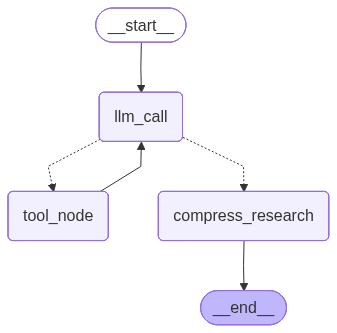

In [233]:
# Graph builder 

from IPython.display import Image , display

agent_builder = StateGraph(ResearcherState , output_schema=ResearcherOutputState)

agent_builder.add_node("llm_call" , llm_call)
agent_builder.add_node("tool_node",tool_node)
agent_builder.add_node("compress_research" , compress_research)

agent_builder.add_edge(START , "llm_call")
agent_builder.add_conditional_edges(
    "llm_call" ,
    should_continue , 
    {
        "tool_node" : "tool_node" , 
        "compress_research" : "compress_research"
    } ,
)
agent_builder.add_edge("tool_node" , "llm_call")
agent_builder.add_edge("compress_research" , END)

researcher_agent = agent_builder.compile()

display(Image(researcher_agent.get_graph().draw_mermaid_png()))

In [234]:
# Run the agent 

from langchain_core.messages import HumanMessage

# Example brief
research_brief = """I want to identify and evaluate the coffee shops in San Francisco that are considered the best based specifically  
on coffee quality. My research should focus on analyzing and comparing coffee shops within the San Francisco area, 
using coffee quality as the primary criterion. I am open regarding methods of assessing coffee quality (e.g.,      
expert reviews, customer ratings, specialty coffee certifications), and there are no constraints on ambiance,      
location, wifi, or food options unless they directly impact perceived coffee quality. Please prioritize primary    
sources such as the official websites of coffee shops, reputable third-party coffee review organizations (like     
Coffee Review or Specialty Coffee Association), and prominent review aggregators like Google or Yelp where direct  
customer feedback about coffee quality can be found. The study should result in a well-supported list or ranking of
the top coffee shops in San Francisco, emphasizing their coffee quality according to the latest available data as  
of July 2025."""

result = researcher_agent.invoke({"researcher_messages": [HumanMessage(content=f"{research_brief}.")]})

for msg in result['researcher_messages'] : 
    msg.pretty_print()

Failed to summarize webpage: Error code: 400 - {'error': {'message': "Failed to call a function. Please adjust your prompt. See 'failed_generation' for more details.", 'type': 'invalid_request_error', 'code': 'tool_use_failed', 'failed_generation': '{\n  "summary": "Q Specialty Coffee, a new cafe, is set to open on Saturday, October 18, in the Pacific Heights neighborhood of San Francisco. The cafe, founded by entrepreneur Cyrus Shen, aims to bring high-quality, specialty coffee to an area lacking strong coffee options. Q Specialty Coffee will offer a variety of coffee drinks, including pourovers, matcha drinks, and nitro cold brew, as well as mille crepes from Lady M Cake Boutique. The cafe will source its green beans from reputable suppliers and roast them on-site using two brand new Bellwether roasters. Shen, who has a background in running restaurants, including Toast\'N Egg and Poke Origin, plans to open more Q Specialty Coffee locations in San Francisco and beyond.",\n  "key_exce

In [235]:
from IPython.display import Markdown
Markdown(result['compressed_research'])

**List of Queries and Tool Calls Made**

1. **tavily_search**: Q Specialty Coffee in San Francisco - gathered information on Q Specialty Coffee's offerings and reputation.
2. **tavily_search**: Eater SF best coffee shops San Francisco 2025 - gathered information on top coffee shops in San Francisco.
3. **tavily_search**: Battle of SF Coffee 2025 Reddit - gathered information on the battle for the best coffee shops in San Francisco.

**Fully Comprehensive Findings**

San Francisco is renowned for its vibrant coffee culture and has been at the forefront of the specialty coffee movement. The city is home to numerous iconic coffee shops, each offering unique experiences and high-quality brews. From longstanding favorites like Saint Frank Coffee and Scullery to newcomers like Q Specialty Coffee and Hedge Coffee Roasters, San Francisco's coffee scene continues to evolve and thrive.

**Q Specialty Coffee**

* Explore Q Specialty Coffee's inviting space, top-notch pour-overs, and delicious matcha drinks. Perfect spot for coffee lovers! [1]
* Q Specialty Coffee, opening Saturday, October 18, serves fancy pourovers and fruity nitro cold brew from Bay Area pros. [2]
* Q Specialty Coffee is located at 3490 California St, Ste A, San Francisco, CA 94118, and operates from 7:00 am to 5:30 pm, Monday through Friday. [3]

**Top Coffee Shops in San Francisco**

* **The Absolute Best San Francisco Coffee Shops** [4]:
	+ Saint Frank Coffee: known for its minimal aesthetic and tea-like Bolivian coffees.
	+ Scullery: a cozy shop serving specialty coffee and top-tier toast.
	+ Sextant Coffee Roasters: offers high-end, affordable beans and delicious pastries.
	+ Telescope Coffee
	+ Abanico Coffee Roasters
	+ SPRO - Mission Dolores/Castro
	+ Grand Coffee
	+ Hey Neighbor Cafe
	+ Excelsior Coffee
	+ Andytown Coffee Roasters
	+ Hi NRG
	+ Paper Son
	+ Shoji
	+ Caffe Trieste
	+ The Coffee Movement at Side A
	+ Q Specialty Coffee
* **The Bougie Bay Area Coffee Upgrade Is Fruit** [5]:
	+ Wasabi lattes, orange juice Americanos, and sliced strawberry garnishes have changed the Bay’s coffee culture for the better.

**Battle of SF Coffee 2025**

* The webpage is about the 'Battle of SF Coffee 2025', a competition to find the best coffee shops in San Francisco. Participants are encouraged to check if their favorite coffee spot is already listed in the thread, upvote their favorites, and comment on spots that have not been posted yet. [6]

**Sources**

[1] Discover Q Specialty Coffee: A San Francisco Gem | TikTok: https://www.tiktok.com/@chaudownfood/video/7576445457287662878
[2] Coffee Nerds and Matcha Stans Will Love This Pac Heights Cafe: https://sf.eater.com/restaurant-news/208595/q-specialty-coffee-opening-pac-heights
[3] Q SPECIALTY COFFEE - Updated December 2025 - Yelp: https://www.yelp.com/biz/q-specialty-coffee-san-francisco
[4] The Absolute Best San Francisco Coffee Shops: https://sf.eater.com/maps/best-coffee-shops-san-francisco
[5] The Bougie Bay Area Coffee Upgrade Is Fruit: https://sf.eater.com/2025/2/21/24368795/fruit-coffee-san-francisco-bay-area-trend
[6] Battle of SF Coffee 2025: https://www.reddit.com/r/sanfrancisco/comments/1li7ro2/battle_of_sf_coffee_2025/